<a href="https://colab.research.google.com/github/Riot808s/FUNDAI-Laboratories-Balona/blob/main/Lab7_Intro_to_ML_Balona.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 7: Supervised vs. Unsupervised Learning, Overfitting, and Cross-Validation

## Fundamentals of Artificial Intelligence

**Name:** Kylle Ian A. Balona
**Course:** BSCSAI
**Section:** 2A
**Date:** 10/20/2026

**Dataset Source (GitHub raw URL):**
https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv

**GitHub URL:** https://github.com/Riot808s/FUNDAI-Laboratories-Balona

## Description
This laboratory compares supervised and unsupervised learning, demonstrates overfitting and underfitting through a complexity sweep, and evaluates models using k-fold cross-validation.

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
      accuracy_score,
      confusion_matrix,
      classification_report,
      adjusted_rand_score,
)

In [79]:
GITHUB_RAW_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(GITHUB_RAW_URL)

print("Dataset shape:", df.shape)
print()
print(df.head())
print()
print("Class distribution:")
print(df["species"].value_counts())


Dataset shape: (150, 5)

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [80]:
feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

X = df[feature_columns].values
y = df["species"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.3,
    stratify = y,
    random_state = 42
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (105, 4)
Testing samples: (45, 4)


## Part A: Supervised Learning (Labels ARE Used)

The model learns a mapping from features to known labels. Scaling is placed INSIDE the pipeline so that each cross-validation fold computes scaling statistics from its training portion only. This prevents data leakage.

In [81]:
supervised_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(max_depth = 3, random_state = 42))
])

supervised_pipeline.fit(X_train, y_train)

supervised_predictions = supervised_pipeline.predict(X_test)

print("SUPERVISED LEARNING RESULTS")
print("=" * 50)
print("Test accuracy:", accuracy_score(y_test, supervised_predictions))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, supervised_predictions))
print()
print(classification_report(y_test, supervised_predictions))

SUPERVISED LEARNING RESULTS
Test accuracy: 0.9777777777777777

Confusion Matrix:
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



## Part B: Unsupervised Learning (Labels ARE NOT Used)

the species column is completely ignored. K-Means must discover group structure on its own.
Afterwards, we compare the discovered clusters to the true labels only for evaluation purposes.

In [82]:
# NOTE: y is NOT used anywhere in this part.
X_unlabeled = df[feature_columns].values

kmeans = KMeans(n_clusters = 3, n_init = 10, random_state = 42)
cluster_labels = kmeans.fit_predict(X_unlabeled)

comparison = pd.crosstab(
    pd.Series(cluster_labels, name = "Discovered Cluster"),
    pd.Series(y, name = "True Species")
)

print("UNSUPERVISED LEARNING RESULTS")
print("=" * 50)
print("Cluster vs. True Species crosstab:")
print(comparison)
print()
print("Adjusted Rand Index (cluster agreement with true labels):")
print(adjusted_rand_score(y, cluster_labels))

UNSUPERVISED LEARNING RESULTS
Cluster vs. True Species crosstab:
True Species        setosa  versicolor  virginica
Discovered Cluster                               
0                        0          48         14
1                       50           0          0
2                        0           2         36

Adjusted Rand Index (cluster agreement with true labels):
0.7302382722834697


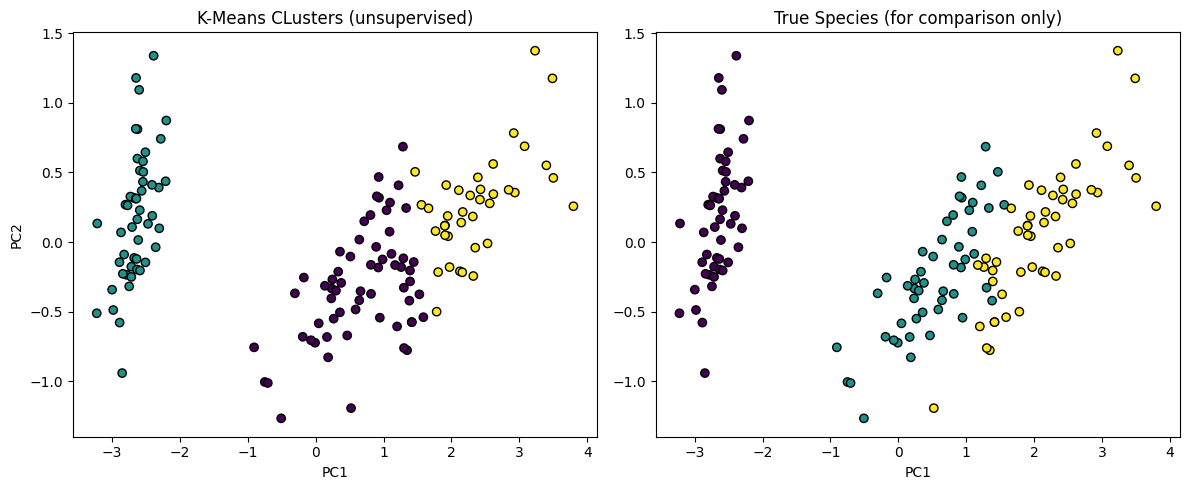

Explained variance ratio: [0.92461872 0.05306648]


In [83]:
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_unlabeled)

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c = cluster_labels, cmap = "viridis", edgecolor = "k")
plt.title("K-Means CLusters (unsupervised)")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
species_codes = pd.factorize(y)[0]
plt.scatter(X_pca[:, 0], X_pca[:, 1], c = species_codes, cmap = "viridis", edgecolor = "k")
plt.title("True Species (for comparison only)")
plt.xlabel("PC1")

plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)

## Part C: Complexity Sweep (Bias-Variance Demonstration)

We train decision trees with increasing max_depth.

- Very small depth -> high bias -> underfitiing
- Moderate depth   -> sweet spot -> good generalization
- Very Large depth -> high variance -> overfitting (train = 100%, gap widens)

In [84]:
depth_values = list(range(1, 16))

train_scores = []
test_scores = []

for depth in depth_values:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth = depth, random_state = 42))
    ])

    pipe.fit(X_train, y_train)

    train_scores.append(accuracy_score(y_train, pipe.predict(X_train)))
    test_scores.append(accuracy_score(y_test, pipe.predict(X_test)))

sweep_table = pd.DataFrame({
    "max_depth": depth_values,
    "train_accuracy": train_scores,
    "test_accuracy": test_scores,
    "gap": np.array(train_scores) - np.array(test_scores)
})

print(sweep_table.to_string(index = False))

 max_depth  train_accuracy  test_accuracy      gap
         1        0.666667       0.666667 0.000000
         2        0.971429       0.888889 0.082540
         3        0.980952       0.977778 0.003175
         4        0.990476       0.888889 0.101587
         5        1.000000       0.911111 0.088889
         6        1.000000       0.911111 0.088889
         7        1.000000       0.911111 0.088889
         8        1.000000       0.911111 0.088889
         9        1.000000       0.911111 0.088889
        10        1.000000       0.911111 0.088889
        11        1.000000       0.911111 0.088889
        12        1.000000       0.911111 0.088889
        13        1.000000       0.911111 0.088889
        14        1.000000       0.911111 0.088889
        15        1.000000       0.911111 0.088889
